In [1]:
import pandas as pd

X_train = pd.read_csv("../data/x_train_final.csv")
y_train = pd.read_csv("../data/y_train_final.csv")
X_test = pd.read_csv("../data/x_test_final.csv")
y_test = pd.read_csv("../data/y_sample_final.csv")


In [2]:
#remove unnecessary columns
X_train = X_train.iloc[:, 2:]
X_test = X_test.iloc[:, 1:]
y_train = y_train.iloc[:, 1:]
y_test = y_test.iloc[:, 1:]
X_train.head

<bound method NDFrame.head of          train gare        date  arret  p2q0  p3q0  p4q0  p0q2  p0q3  p0q4
0       VBXNMF  KYF  2023-04-03      8   0.0   0.0   1.0  -3.0  -1.0  -2.0
1       VBXNMF  JLR  2023-04-03      9   0.0   0.0   0.0   1.0   0.0   1.0
2       VBXNMF  EOH  2023-04-03     10  -1.0   0.0   0.0  -1.0   0.0   0.0
3       VBXNMF  VXY  2023-04-03     11  -1.0  -1.0   0.0   2.0  -2.0   0.0
4       VBXNMF  OCB  2023-04-03     12  -1.0  -1.0  -1.0  -1.0   3.0   2.0
...        ...  ...         ...    ...   ...   ...   ...   ...   ...   ...
667259  BFNJJK  DGG  2023-11-10     22   0.0  -1.0  -6.0  -1.0   0.0  -2.0
667260  BFNJJK  KDN  2023-11-10     23   0.0   0.0  -1.0   1.0   0.0   0.0
667261  BFNJJK  TVD  2023-11-10     24   1.0   0.0   0.0  -1.0  -3.0  -1.0
667262  BFNJJK  TXP  2023-11-10     26   2.0   2.0   1.0   0.0   0.0   1.0
667263  BFNJJK  OWI  2023-11-10     28   1.0   1.0   2.0  -5.0  -4.0  -4.0

[667264 rows x 10 columns]>

In [3]:
X_train.describe()

,arret,p2q0,p3q0,p4q0,p0q2,p0q3,p0q4
count,667264.000000,667264.000000,667264.000000,667264.000000,667264.000000,667264.000000,667264.000000
mean,18.277499,-0.170696,-0.167304,-0.176308,-0.163223,-0.173579,-0.174436
std,7.030424,1.976521,1.960416,1.926275,1.988527,2.643148,4.732999
min,7.000000,-160.000000,-160.000000,-160.000000,-160.000000,-1441.000000,-1441.000000
25%,12.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
50%,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,24.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,42.000000,14.000000,15.000000,15.000000,15.000000,15.000000,15.000000


In [4]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train.squeeze(),
    test_size=0.2,
    random_state=42
)

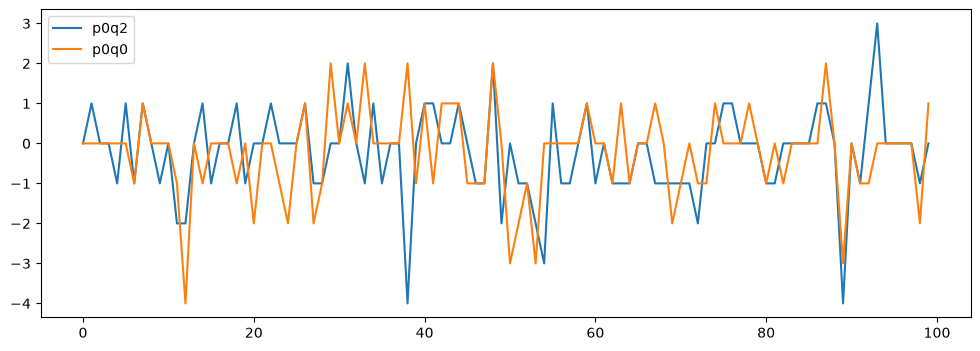

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.plot(X_fit["p0q2"].iloc[:100].to_numpy(), label="p0q2")
plt.plot(y_fit.iloc[:100].to_numpy(), label="p0q0")

plt.legend()
plt.show()

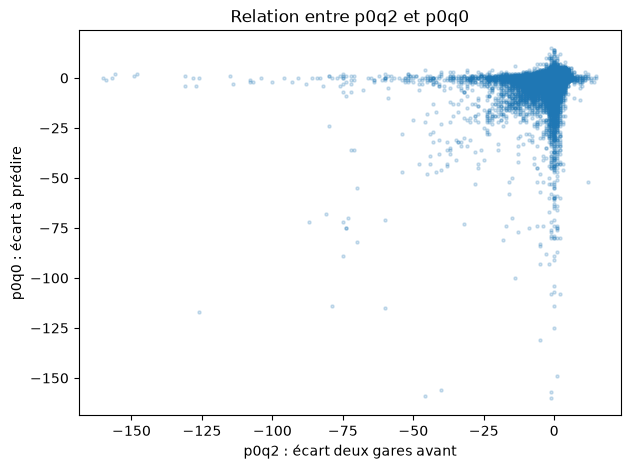

In [6]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_fit["p0q2"],
    y_fit.squeeze(),
    alpha=0.2,
    s=5
)

plt.xlabel("p0q2 : écart deux gares avant")
plt.ylabel("p0q0 : écart à prédire")
plt.title("Relation entre p0q2 et p0q0")

plt.show()

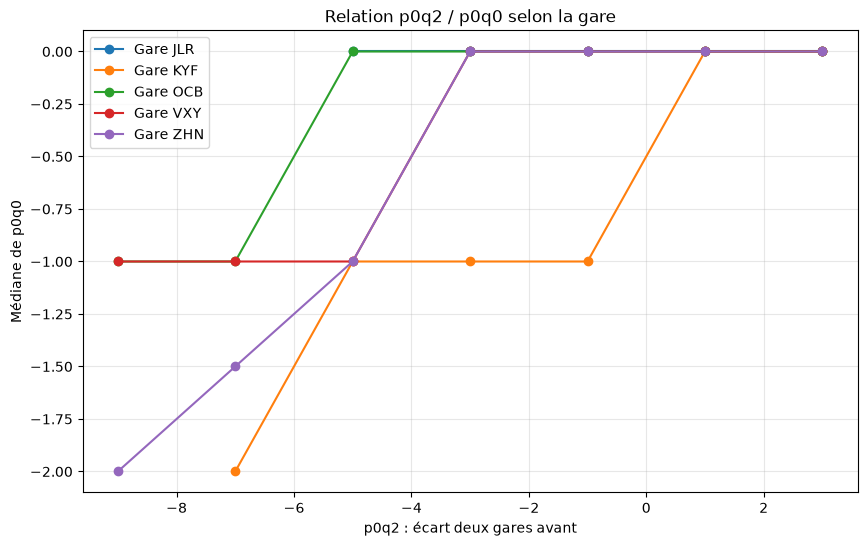

In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Construire un DataFrame commun
df = pd.DataFrame({
    "p0q2": X_fit["p0q2"].to_numpy(),
    "p0q0": np.asarray(y_fit).ravel(),
    "gare": X_fit["gare"].to_numpy(),
    "train": X_fit["train"].to_numpy()
}).dropna()

# Choisir les 5 gares les plus représentées
top_gares = df["gare"].value_counts().head(5).index
df_g = df[df["gare"].isin(top_gares)].copy()

# Regrouper p0q2 en intervalles de 2 minutes
df_g["bin"] = pd.cut(
    df_g["p0q2"],
    bins=np.arange(-10, 12, 2)
)

# Médiane de p0q0 pour chaque gare et chaque intervalle
stats = (
    df_g.groupby(["gare", "bin"], observed=True)["p0q0"]
    .agg(median="median", count="size")
    .reset_index()
)

# Écarter les groupes avec trop peu d'observations
stats = stats[stats["count"] >= 30].copy()
stats["centre"] = stats["bin"].apply(lambda b: b.mid).astype(float)

# Afficher les courbes
plt.figure(figsize=(10, 6))

for gare, group in stats.groupby("gare"):
    group = group.sort_values("centre")
    plt.plot(
        group["centre"],
        group["median"],
        marker="o",
        label=f"Gare {gare}"
    )

plt.xlabel("p0q2 : écart deux gares avant")
plt.ylabel("Médiane de p0q0")
plt.title("Relation p0q2 / p0q0 selon la gare")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Échantillon aléatoire de 100 000 observations
X_sample = X_fit.sample(
    n=min(100_000, len(X_fit)),
    random_state=42
)

# Garder les mêmes observations pour la cible
y_sample = y_fit.loc[X_sample.index]

# Une seule variable explicative
X = X_sample[["p0q2"]]

model = LinearRegression()
model.fit(X, y_sample)

# Prédiction
y_pred = model.predict(X_val[["p0q2"]])

print("MAE :", mean_absolute_error(y_val, y_pred))
print("Coefficient :", model.coef_)
print("Intercept :", model.intercept_)

MAE : 0.9110633574410216
Coefficient : [0.29018623]
Intercept : -0.11560316405201254


In [9]:
features = [
    "p0q2", "p0q3", "p0q4",
    "p2q0", "p3q0", "p4q0"
]

model = LinearRegression()

model.fit(X_sample[features], y_sample)

y_pred = model.predict(X_val[features])

print("MAE :", mean_absolute_error(y_val, y_pred))

MAE : 0.8872350552176114


In [11]:
import numpy as np
from sklearn.linear_model import LinearRegression, QuantileRegressor
from sklearn.metrics import mean_absolute_error

features = [
    "p0q2", "p0q3", "p0q4",
    "p2q0", "p3q0", "p4q0"
]

models = {
    "LinearRegression (MSE)": LinearRegression(),
}

for name, model in models.items():
    model.fit(X_fit[features], np.asarray(y_fit).ravel())

    pred = model.predict(X_val[features])
    mae = mean_absolute_error(y_val, pred)

    print(f"{name}: MAE = {mae:.4f}")

LinearRegression (MSE): MAE = 0.8814


- pour le moment on a teste avec des regression lineaire qui minimise l'erreur quadratique
- essayons un modele qui minimise directement l erreur absolue, qu on essaye de minimiser

In [14]:
X_small = X_fit[features].sample(n=50_000, random_state=42)
y_small = y_fit.loc[X_small.index]

model = QuantileRegressor(
    quantile=0.5,
    alpha=0,
    solver="highs"
)

model.fit(X_small, y_small)
pred = model.predict(X_val[features])

print("MAE :", mean_absolute_error(y_val, pred))

MAE : 0.8594215296422624


## Relation non lineaire ?
- jusque la on peut dire qu on a plafonne la mae avec les modeles lineaires de regression
- essayons avec des modeles non lineaires

In [15]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

model = DecisionTreeRegressor(
    criterion="absolute_error",
    max_depth=5,
    min_samples_leaf=100,
    random_state=42
)

model.fit(X_sample[features], y_sample)

pred = model.predict(X_val[features])

print("MAE arbre :", mean_absolute_error(y_val, pred))

MAE arbre : 0.816482207219021


- meilleur depth avec cross validation ??

In [16]:
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, GroupKFold

features = [
    "p0q2", "p0q3", "p0q4",
    "p2q0", "p3q0", "p4q0"
]

# Échantillon pour accélérer les expériences
X_cv = X_fit.sample(
    n=min(20_000, len(X_fit)),
    random_state=42
)
y_cv = y_fit.loc[X_cv.index]

# Regrouper les observations appartenant à la même date
groups = pd.to_datetime(X_cv["date"]).dt.date

tree = DecisionTreeRegressor(
    criterion="absolute_error",
    min_samples_leaf=100,
    random_state=42
)

param_grid = {
    "max_depth": [2, 3, 5, 7, 10, 15]
}

grid = GridSearchCV(
    estimator=tree,
    param_grid=param_grid,
    cv=GroupKFold(n_splits=5),
    scoring="neg_mean_absolute_error",
    return_train_score=True,
    n_jobs=2
)

grid.fit(X_cv[features], y_cv, groups=groups)

print("Meilleure profondeur :", grid.best_params_)
print("Meilleure MAE CV :", -grid.best_score_)

Meilleure profondeur : {'max_depth': 15}
Meilleure MAE CV : 0.8216567218463817


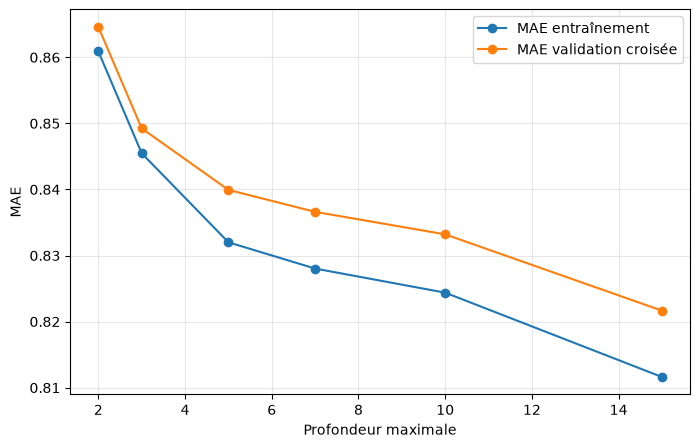

In [17]:
import matplotlib.pyplot as plt

results = pd.DataFrame(grid.cv_results_)

depths = results["param_max_depth"].astype(int)

plt.figure(figsize=(8, 5))

plt.plot(
    depths,
    -results["mean_train_score"],
    marker="o",
    label="MAE entraînement"
)

plt.plot(
    depths,
    -results["mean_test_score"],
    marker="o",
    label="MAE validation croisée"
)

plt.xlabel("Profondeur maximale")
plt.ylabel("MAE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [18]:
from sklearn.metrics import mean_absolute_error

best_tree = grid.best_estimator_

pred = best_tree.predict(X_val[features])

print("MAE validation :", mean_absolute_error(y_val, pred))

MAE validation : 0.818969974447933


- autre CV, cette fois sur max_depth et min_samples_leaf

In [19]:
tree = DecisionTreeRegressor(
    criterion="absolute_error",
    random_state=42
)

param_grid = {
    "max_depth": [5, 10, 15, None],
    "min_samples_leaf": [20, 100]
}

grid = GridSearchCV(
    estimator=tree,
    param_grid=param_grid,
    cv=GroupKFold(n_splits=5),
    scoring="neg_mean_absolute_error",
    return_train_score=True,
    n_jobs=2
)

grid.fit(X_cv[features], y_cv, groups=groups)

print("Meilleure profondeur :", grid.best_params_)
print("Meilleure MAE CV :", -grid.best_score_)

Meilleure profondeur : {'max_depth': None, 'min_samples_leaf': 20}
Meilleure MAE CV : 0.8118178161487707


In [20]:
import pandas as pd

results = pd.DataFrame(grid.cv_results_)

comparison = results[[
    "param_max_depth",
    "param_min_samples_leaf",
    "mean_train_score",
    "mean_test_score"
]].copy()

comparison["train_mae"] = -comparison["mean_train_score"]
comparison["cv_mae"] = -comparison["mean_test_score"]

print(comparison[[
    "param_max_depth",
    "param_min_samples_leaf",
    "train_mae",
    "cv_mae"
]].sort_values("cv_mae"))

  param_max_depth  param_min_samples_leaf  train_mae    cv_mae
6            None                      20   0.767716  0.811818
7            None                     100   0.804955  0.816897
5              15                     100   0.811617  0.821657
4              15                      20   0.804041  0.830097
3              10                     100   0.824380  0.833205
2              10                      20   0.812940  0.834456
0               5                      20   0.825890  0.837230
1               5                     100   0.832001  0.839936


- on passe a du gradient boosting

In [21]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score, GroupKFold

model = HistGradientBoostingRegressor(
    loss="absolute_error",
    max_iter=150,
    learning_rate=0.05,
    max_leaf_nodes=15,
    random_state=42
)

scores = cross_val_score(
    model,
    X_cv[features],
    y_cv,
    groups=groups,
    cv=GroupKFold(n_splits=5),
    scoring="neg_mean_absolute_error",
    n_jobs=2
)

print("MAE CV :", -scores.mean())
print("Écart-type :", scores.std())

MAE CV : 0.8248740857001711
Écart-type : 0.04054984469855761


- essayons d ameliorer le gradient boosting en faisant une recherche d hyperparametres

In [22]:
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

# Même dataset et mêmes groupes que pour CART
groups = pd.to_datetime(X_cv["date"]).dt.date

model = HistGradientBoostingRegressor(
    loss="absolute_error",
    early_stopping=False,
    random_state=42
)

param_grid = {
    "max_iter": [150, 300, 500],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 1.0]
}

search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=15,
    cv=GroupKFold(n_splits=5),
    scoring="neg_mean_absolute_error",
    n_jobs=2,
    random_state=42,
    return_train_score=True,
    verbose=1
)

search.fit(X_cv[features], y_cv, groups=groups)

print("Meilleurs paramètres :", search.best_params_)
print("Meilleure MAE CV :", -search.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Meilleurs paramètres : {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 300, 'learning_rate': 0.03, 'l2_regularization': 0.0}
Meilleure MAE CV : 0.8107043802761489


In [23]:
results = pd.DataFrame(search.cv_results_)

results["train_mae"] = -results["mean_train_score"]
results["cv_mae"] = -results["mean_test_score"]

cols = [
    "param_max_iter",
    "param_learning_rate",
    "param_max_leaf_nodes",
    "param_min_samples_leaf",
    "param_l2_regularization",
    "train_mae",
    "cv_mae",
    "std_test_score"
]

print(
    results[cols]
    .sort_values("cv_mae")
    .head(10)
    .to_string(index=False)
)

 param_max_iter  param_learning_rate  param_max_leaf_nodes  param_min_samples_leaf  param_l2_regularization  train_mae   cv_mae  std_test_score
            300                 0.03                    63                      20                      0.0   0.791888 0.810704        0.036901
            500                 0.03                    63                      20                      0.0   0.791359 0.810778        0.036647
            500                 0.05                    63                      20                      0.0   0.792391 0.811119        0.037095
            300                 0.10                    31                      20                      0.0   0.802676 0.813872        0.036515
            150                 0.03                    31                      20                      1.0   0.804270 0.814370        0.036039
            500                 0.10                    31                     100                      1.0   0.807399 0.814737        0

In [24]:
import numpy as np
import pandas as pd

cart_scores = -np.array([
    grid.cv_results_[f"split{i}_test_score"][grid.best_index_]
    for i in range(5)
])

gb_scores = -np.array([
    search.cv_results_[f"split{i}_test_score"][search.best_index_]
    for i in range(5)
])

comparison = pd.DataFrame({
    "CART": cart_scores,
    "Gradient Boosting": gb_scores,
    "Différence CART - GB": cart_scores - gb_scores
})

print(comparison)

       CART  Gradient Boosting  Différence CART - GB
0  0.882368           0.877093              0.005275
1  0.825951           0.820504              0.005447
2  0.786234           0.780162              0.006071
3  0.776500           0.775032              0.001468
4  0.788037           0.800731             -0.012694


In [25]:
from sklearn.model_selection import GroupKFold
import pandas as pd

cv = GroupKFold(n_splits=5)

for i, (_, val_idx) in enumerate(
    cv.split(X_cv[features], y_cv, groups=groups)
):
    y_fold = y_cv.iloc[val_idx]

    print(f"\nPli {i}")
    print("Observations :", len(y_fold))
    print("Médiane :", y_fold.median())
    print("Écart-type :", y_fold.std())
    print("Proportion y=0 :", (y_fold == 0).mean())


Pli 0
Observations : 3987
Médiane : 0.0
Écart-type : 1.7748223164691297
Proportion y=0 : 0.3880110358665663

Pli 1
Observations : 3996
Médiane : 0.0
Écart-type : 2.5631606481848284
Proportion y=0 : 0.4461961961961962

Pli 2
Observations : 3988
Médiane : 0.0
Écart-type : 2.118463010690535
Proportion y=0 : 0.43681043129388164

Pli 3
Observations : 4000
Médiane : 0.0
Écart-type : 2.0730041664378094
Proportion y=0 : 0.43125

Pli 4
Observations : 4029
Médiane : 0.0
Écart-type : 1.8042364273076203
Proportion y=0 : 0.43658476048647304


- le gradient boosting n a pas rapporte une grande ameliorations
- essayons le random forest

In [26]:

import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

rf = RandomForestRegressor(
    criterion="squared_error",
    bootstrap=True,
    random_state=42,
    n_jobs=1
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [12, None],
    "min_samples_leaf": [5, 20, 50],
    "max_features": [0.5, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=12,
    cv=GroupKFold(n_splits=5),
    scoring="neg_mean_absolute_error",
    n_jobs=2,
    random_state=42,
    return_train_score=True,
    verbose=1
)

rf_search.fit(
    X_cv[features],
    y_cv,
    groups=groups
)

print("Meilleurs HP :", rf_search.best_params_)
print("Meilleure MAE CV :", -rf_search.best_score_)


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleurs HP : {'n_estimators': 100, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 12}
Meilleure MAE CV : 0.8572578977092137


In [27]:

results_rf = pd.DataFrame(rf_search.cv_results_)

results_rf["train_mae"] = -results_rf["mean_train_score"]
results_rf["cv_mae"] = -results_rf["mean_test_score"]

cols = [
    "param_n_estimators",
    "param_max_depth",
    "param_min_samples_leaf",
    "param_max_features",
    "train_mae",
    "cv_mae",
    "std_test_score"
]

print(
    results_rf[cols]
    .sort_values("cv_mae")
    .head(10)
    .to_string(index=False)
)


 param_n_estimators param_max_depth  param_min_samples_leaf  param_max_features  train_mae   cv_mae  std_test_score
                100              12                      20                 0.5   0.834421 0.857258        0.033359
                200              12                       5                 0.5   0.806163 0.859816        0.035210
                100              12                       5                 0.5   0.806259 0.859985        0.034996
                100              12                      20                 1.0   0.831868 0.860164        0.032578
                200              12                      20                 1.0   0.831903 0.860528        0.033084
                200              12                      50                 0.5   0.848048 0.860815        0.036821
                100            None                      50                 0.5   0.848250 0.861320        0.036547
                200            None                      20             

In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_score
import pandas as pd

idx = X_cv.sample(n=5000, random_state=42).index

X_small = X_cv.loc[idx, features]
y_small = y_cv.loc[idx]
groups_small = pd.to_datetime(X_cv.loc[idx, "date"]).dt.date

for criterion in ["squared_error", "absolute_error"]:

    rf = RandomForestRegressor(
        n_estimators=40,
        criterion=criterion,
        max_depth=12,
        min_samples_leaf=20,
        max_features=0.5,
        n_jobs=-1,
        random_state=42
    )

    scores = cross_val_score(
        rf,
        X_small,
        y_small,
        groups=groups_small,
        cv=GroupKFold(n_splits=3),
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    print(f"{criterion}: MAE = {-scores.mean():.4f}")

squared_error: MAE = 0.8575
absolute_error: MAE = 0.8204
